In [1]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Python/GitHub/goals-championship/csv/fotmob_match_stats.csv')
df.head(2)

,matchId,matchRound,homeTeamName,homeTeamid,awayTeamName,awayTeamid,home_goals,away_goals,ball_possession_home,ball_possession_away,...,ground_duels_won_home,ground_duels_won_away,aerial_won_home,aerial_won_away,dribbles_succeeded_home,dribbles_succeeded_away,yellow_cards_home,yellow_cards_away,red_cards_home,red_cards_away
0,5836754,1,Wolverhampton Wanderers,8602,Blackburn Rovers,8655,2,2,55,45,...,40 (56%),31 (44%),15 (48%),16 (52%),8 (44%),7 (41%),1,3,0,0
1,5836755,1,Bolton Wanderers,8559,Preston North End,8411,2,1,55,45,...,30 (48%),33 (52%),18 (49%),19 (51%),5 (38%),6 (55%),2,3,0,0


In [2]:
df = df.drop(37).reset_index(drop=True)
df = df.drop(46).reset_index(drop=True)

In [ ]:
df.columns

Index(['matchId', 'matchRound', 'homeTeamName', 'homeTeamid', 'awayTeamName',
       'awayTeamid', 'home_goals', 'away_goals', 'ball_possession_home',
       'ball_possession_away', 'big_chances_home', 'big_chances_away',
       'big_chances_missed_home', 'big_chances_missed_away', 'fouls_home',
       'fouls_away', 'corners_home', 'corners_away', 'total_shots_home',
       'total_shots_away', 'shots_off_target_home', 'shots_off_target_away',
       'shots_on_target_home', 'shots_on_target_away', 'blocked_shots_home',
       'blocked_shots_away', 'hit_woodwork_home', 'hit_woodwork_away',
       'shots_inside_box_home', 'shots_inside_box_away',
       'shots_outside_box_home', 'shots_outside_box_away', 'xG_home',
       'xG_away', 'xG_open_play_home', 'xG_open_play_away', 'xG_set_play_home',
       'xG_set_play_away', 'xG_non_penalty_home', 'xG_non_penalty_away',
       'xGOT_home', 'xGOT_away', 'passes_home', 'passes_away',
       'accurate_passes_home', 'accurate_passes_away', 'own_ha

In [5]:
xG_df = df.groupby(by='homeTeamName').agg({
    'home_goals': 'sum',
    'away_goals': 'sum',
    'xG_home': 'sum',
    'xG_away': 'sum',
}).reset_index().sort_values(by='home_goals', ascending=False)

# df.groupby(by='awayTeamName').agg(
#     goals=('home_goals', 'sum'),
#     xG=('xG_home', 'sum')
# )
xG_df

,homeTeamName,home_goals,away_goals,xG_home,xG_away
16,Southampton,22,5,17.82,9.76
5,Cardiff City,21,13,21.77,12.53
9,Middlesbrough,19,9,15.24,7.82
0,Birmingham City,19,8,13.21,11.24
21,West Ham United,19,12,18.72,8.40
14,Queens Park Rangers,16,7,17.49,7.85
22,Wolverhampton Wanderers,15,8,16.12,5.61
11,Norwich City,15,13,11.79,11.46
10,Millwall,15,10,15.15,11.30
1,Blackburn Rovers,14,10,11.26,10.31


In [20]:
# get only teams with bigger xG than goals
xG_df[xG_df['xG_home'] > xG_df['home_goals']]

,homeTeamName,home_goals,away_goals,xG_home,xG_away,diff,xG_bigger
5,Cardiff City,21,13,21.77,12.53,0.77,True
14,Queens Park Rangers,16,7,17.49,7.85,1.49,True
22,Wolverhampton Wanderers,15,8,16.12,5.61,1.12,True
10,Millwall,15,10,15.15,11.30,0.15,True
20,West Bromwich Albion,13,7,15.43,8.64,2.43,True
18,Swansea City,13,5,14.03,11.25,1.03,True
2,Bolton Wanderers,10,16,12.36,15.10,2.36,True
13,Preston North End,8,13,10.16,12.74,2.16,True
8,Lincoln City,8,17,12.53,12.03,4.53,True
6,Charlton Athletic,7,7,7.48,8.84,0.48,True


In [14]:
# find the team with most xG compared to goals
xG_df['diff'] = xG_df['xG_home'] - xG_df['home_goals']
result = xG_df.loc[xG_df['diff'].idxmax()]
print(result)

homeTeamName    Bristol City
home_goals                 4
away_goals                13
xG_home                 9.07
xG_away                 12.6
diff                    5.07
Name: 3, dtype: object


In [18]:
xG_df

,homeTeamName,home_goals,away_goals,xG_home,xG_away,diff,xG_bigger
16,Southampton,22,5,17.82,9.76,-4.18,False
5,Cardiff City,21,13,21.77,12.53,0.77,True
9,Middlesbrough,19,9,15.24,7.82,-3.76,False
0,Birmingham City,19,8,13.21,11.24,-5.79,False
21,West Ham United,19,12,18.72,8.40,-0.28,False
14,Queens Park Rangers,16,7,17.49,7.85,1.49,True
22,Wolverhampton Wanderers,15,8,16.12,5.61,1.12,True
11,Norwich City,15,13,11.79,11.46,-3.21,False
10,Millwall,15,10,15.15,11.30,0.15,True
1,Blackburn Rovers,14,10,11.26,10.31,-2.74,False


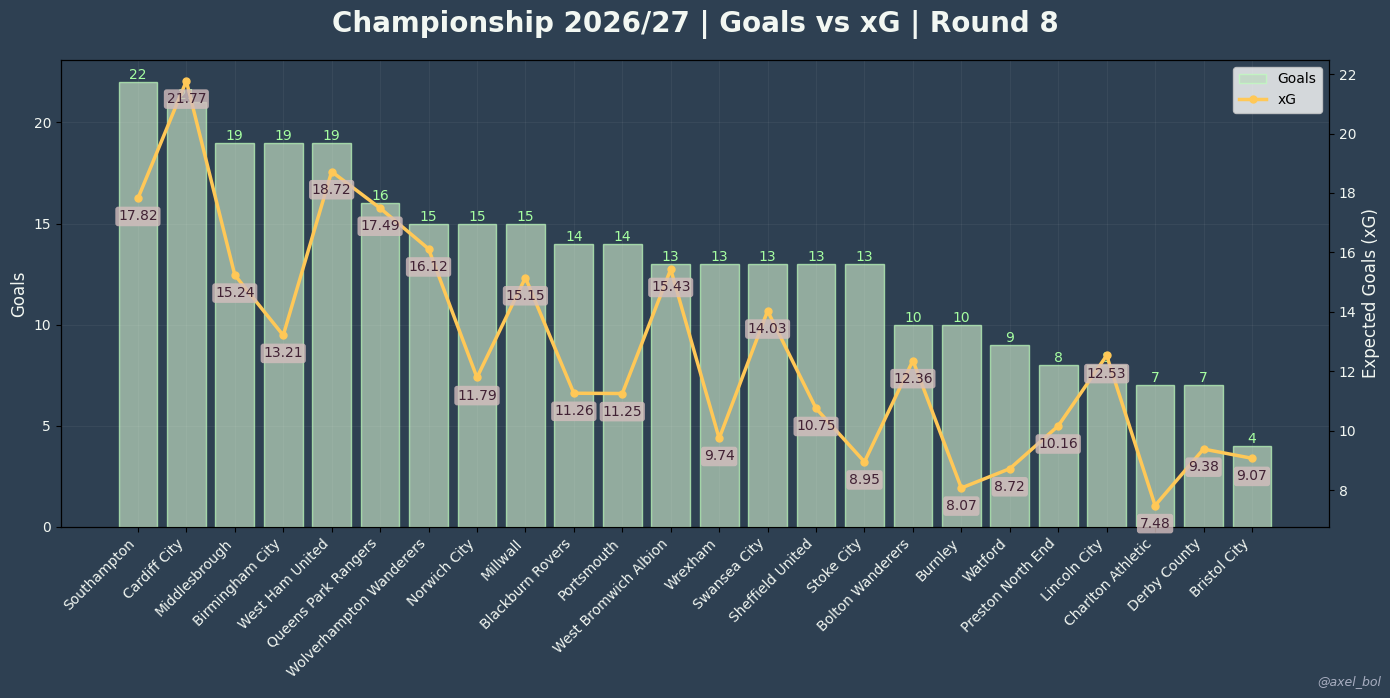

In [ ]:
# Goals vs Avg xG

import matplotlib.pyplot as plt

# Ordenar por Avg xG de mayor a menor
c_df_sorted = xG_df.sort_values('home_goals', ascending=False)

# Figura
fig, ax1 = plt.subplots(figsize=(14, 7), facecolor="#2E4052")
ax1.set_facecolor("#2E4052")

# X positions
x = range(len(c_df_sorted))

# --- BAR: Avg xG ---
bars = ax1.bar(
    x,
    c_df_sorted['home_goals'],
    color='#BDD9BF',
    edgecolor='#BFFFBC',
    alpha=0.7,
    label='Goals'
)

# Valores encima de las barras
for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height}',
        #f'{height:.2f}',
        ha='center',
        va='bottom',
        fontsize=10,
        color='#A6FFA1'
    )

# Eje izquierdo
#ax1.set_xlabel('Team Name', fontsize=12, fontweight='bold')
ax1.set_ylabel('Goals', fontsize=12, color='#F2F7F2')
ax1.tick_params(axis='y', labelcolor='#F2F7F2')

# --- LINE: Goals ---
ax2 = ax1.twinx()

ax2.plot(
    x,
    c_df_sorted['xG_home'],
    color='#FFC857',
    marker='o',
    markersize=5,
    linewidth=2.5,
    linestyle='-',
    label='xG'
)

# For que añade los valores encima de cada punto
for i, goals in enumerate(c_df_sorted['xG_home']):
    plt.annotate(
        # texto a mostrar
        f"{goals:.2f}",
        # posición del punto (índice, valor)
        xy=(i, goals),
        # desplazamiento en puntos (x, y)
        xytext=(0, -8),
        textcoords='offset points',
        ha='center',
        va='top',
        fontsize=10,
        #fontweight='bold',
        color='#412234',
        bbox=dict(boxstyle='round,pad=0.2', fc='#D4BEBE', ec='none', alpha=0.8)
    )

# Eje derecho
ax2.set_ylabel('Expected Goals (xG)', fontsize=12, color='#F2F7F2')
ax2.tick_params(axis='y', labelcolor='#F2F7F2')

# Nombres de equipos
ax1.set_xticks(x)
ax1.set_xticklabels(
    c_df_sorted['homeTeamName'],
    rotation=45,
    ha='right',
    color='#F2F7F2'
)

# Título
plt.title(
    'Championship 2026/27 | Goals vs xG | Round 16',
    fontsize=20,
    fontweight='bold',
    pad=20,
    color='#F2F7F2'
)

# Grid solamente para goals
ax1.grid(
    True,
    axis='both',
    alpha=0.05,
    color='#FFFFFF'
)

# Combinar las leyendas de ambos ejes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper right',
    frameon=True
)

# Firma
plt.figtext(
    0.99,
    0.01,
    '@axel_bol',
    ha='right',
    va='bottom',
    fontsize=9,
    color='#A8AEC1',
    fontstyle='italic'
)

plt.tight_layout()
plt.savefig(r'/content/drive/MyDrive/Python/GitHub/goals-championship/wrongxGvsGoals.png', dpi=300, bbox_inches='tight', pad_inches=0.35, transparent=False)
plt.show()

In [ ]:
df.groupby(by='homeTeamName')['xG_home'].sum().reset_index().sort_values(by='xG_home', ascending=False)

,homeTeamName,xG_home
5,Cardiff City,21.77
21,West Ham United,18.72
16,Southampton,17.82
14,Queens Park Rangers,17.49
22,Wolverhampton Wanderers,16.12
20,West Bromwich Albion,15.43
9,Middlesbrough,15.24
10,Millwall,15.15
18,Swansea City,14.03
0,Birmingham City,13.21
